In [1]:
import os
from dotenv import load_dotenv
import pandas as pd
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

# Load .env from the project root (one folder up from notebooks/)
load_dotenv(dotenv_path="../.env")

connection_url = URL.create(
    drivername="postgresql+psycopg2",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT", 5432)),
    database=os.getenv("DB_NAME"),
)

engine = create_engine(connection_url)

# Query our pre-aggregated mart instead of the raw 18,570 rows
query = "SELECT * FROM mart_daily_sales ORDER BY order_date;"
df = pd.read_sql(query, engine, parse_dates=["order_date"])

print(f"Loaded {len(df)} trading days.")
df.head()

Loaded 241 trading days.


,order_date,day_of_week,total_orders,total_revenue,avg_order_value,card_revenue,cash_revenue,bulk_order_count,rolling_7d_avg_revenue,prev_day_revenue
0,2025-11-03,Monday,68,3279.0,48.22,2797.0,482.0,0,3279.00,NaN
1,2025-11-04,Tuesday,69,2730.0,39.57,2222.0,508.0,0,3004.50,3279.0
2,2025-11-05,Wednesday,78,4549.0,58.32,4224.0,325.0,1,3519.33,2730.0
3,2025-11-06,Thursday,71,3700.0,52.11,3346.0,354.0,0,3564.50,4549.0
4,2025-11-07,Friday,92,4202.0,45.67,3697.0,505.0,0,3692.00,3700.0


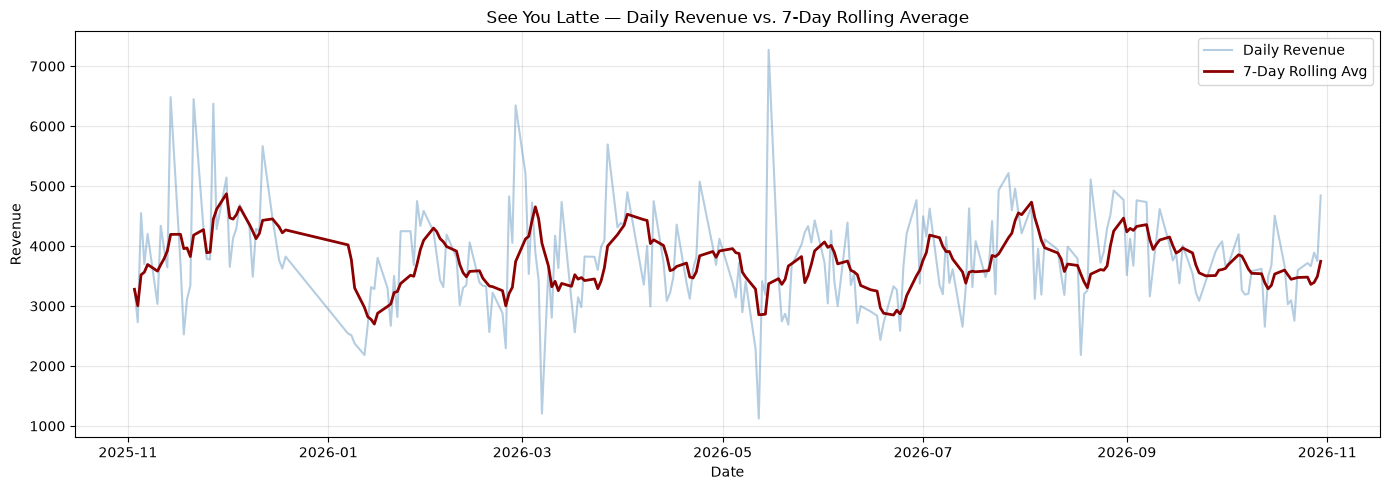

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(
    df["order_date"],
    df["total_revenue"],
    alpha=0.4,
    label="Daily Revenue",
    color="steelblue",
)
plt.plot(
    df["order_date"],
    df["rolling_7d_avg_revenue"],
    linewidth=2,
    label="7-Day Rolling Avg",
    color="darkred",
)

plt.title("See You Latte — Daily Revenue vs. 7-Day Rolling Average")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# 1. Create the leakage-free 7-day rolling average (strictly past 7 trading days)
df["prev_7d_avg_revenue"] = df["rolling_7d_avg_revenue"].shift(1)  # <-- ADD THIS

# 2. Drop the very first row where prev_day_revenue / prev_7d_avg_revenue are NaN
model_df = df.dropna(subset=["prev_day_revenue", "prev_7d_avg_revenue"]).copy()  # <-- UPDATE THIS

# 3. Extract month as a numeric feature
model_df["month"] = model_df["order_date"].dt.month

# 4. One-hot encode day_of_week
model_df = pd.get_dummies(model_df, columns=["day_of_week"], drop_first=True)

# 5. Define features (X) and target (y) — using the clean rolling average
feature_cols = ["prev_day_revenue", "prev_7d_avg_revenue", "month"] + [  # <-- SWAP HERE
    col for col in model_df.columns if col.startswith("day_of_week_")
]

X = model_df[feature_cols]
y = model_df["total_revenue"]

# 6. Chronological 80/20 split
split_idx = int(len(model_df) * 0.8)

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
dates_test = model_df["order_date"].iloc[split_idx:]

print(f"Training days: {len(X_train)} | Testing days: {len(X_test)}")

Training days: 192 | Testing days: 48


Mean Absolute Error (MAE): 484.35


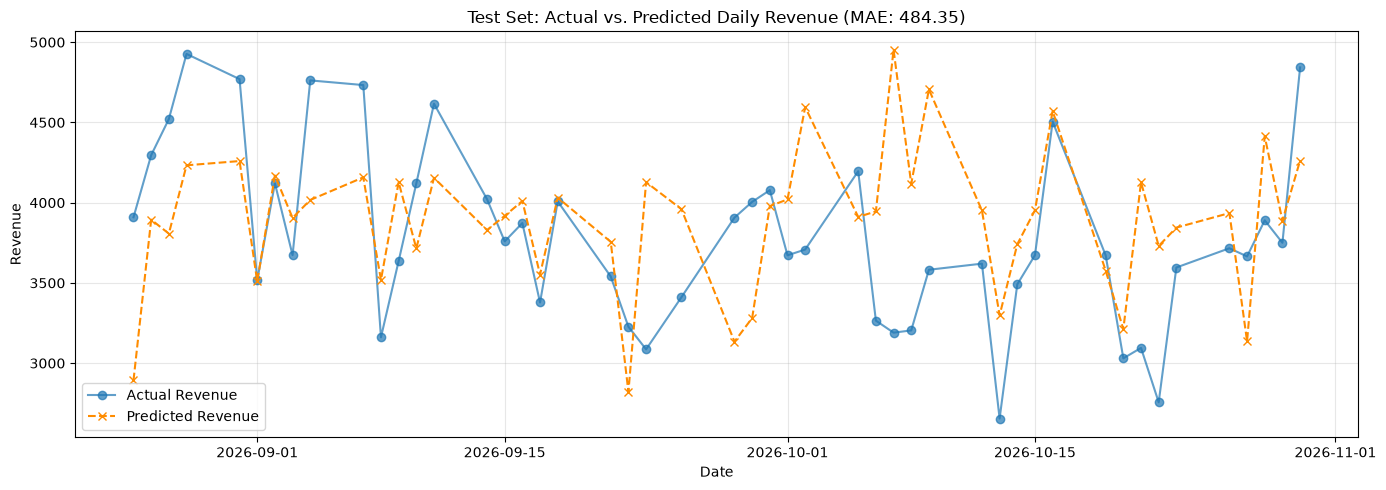

In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# 1. Initialize and train the model
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 2. Predict on the unseen future test days
predictions = model.predict(X_test)

# 3. Evaluate accuracy
mae = mean_absolute_error(y_test, predictions)
print(f"Mean Absolute Error (MAE): {mae:.2f}")

# 4. Plot Actual vs. Predicted on the Test Set
plt.figure(figsize=(14, 5))
plt.plot(dates_test, y_test, label="Actual Revenue", marker="o", alpha=0.7)
plt.plot(
    dates_test,
    predictions,
    label="Predicted Revenue",
    linestyle="--",
    marker="x",
    color="darkorange",
)

plt.title(f"Test Set: Actual vs. Predicted Daily Revenue (MAE: {mae:.2f})")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()